# 版本 15：外部数据集微调 (Fine-tuning 域适应)
- **核心目标**：使用外部数据集（andrewmvd）对 v13 模型进行微调，缓解域偏移。
- **数据划分**：16 个 CT 卷用于训练，4 个 CT 卷用于验证。
- **策略**：使用较小学习率 (1e-4) 进行微调，记录全新的 Loss 和 Dice 曲线。
- **预期**：Loss 会下降，外部 Dice 分数会显著回升，证明微调是解决跨中心差异的有效手段。

# #修复版单元格 1：数据加载（加入 HU 窗宽窗位与正确的标准化）# 

In [1]:
#修复版单元格 1：数据加载（加入 HU 窗宽窗位与正确的标准化）
!pip install monai
!pip install nibabel

import os
import random
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
import nibabel as nib
from monai.networks.nets import AttentionUnet
from monai.losses import DiceCELoss
from monai.metrics import DiceMetric

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"使用设备: {device}")

class ExternalNiftiFineTuneDataset(Dataset):
    def __init__(self, image_paths, mask_paths, target_size=(256, 256), slice_step=3):
        self.target_size = target_size
        self.data_pairs = []
        
        print("正在解析 3D 卷并提取切片...")
        for img_path, mask_path in zip(image_paths, mask_paths):
            img_3d = nib.load(img_path).get_fdata()
            mask_3d = nib.load(mask_path).get_fdata()
            depth = img_3d.shape[2]
            
            for i in range(0, depth, slice_step):
                img_2d = img_3d[:, :, i]
                mask_2d = mask_3d[:, :, i]
                
                # 🔥 核心修复：应用 CT 肺窗 (-1000 到 400 HU)
                img_2d = np.clip(img_2d, -1000, 400)
                img_2d = (img_2d - (-1000)) / (400 - (-1000)) # 归一化到 0-1
                
                # 处理掩码
                mask_2d = (mask_2d > 0.5).astype(np.float32)
                
                # 转为 Tensor 并缩放
                img_tensor = torch.from_numpy(img_2d).unsqueeze(0).float()
                mask_tensor = torch.from_numpy(mask_2d).unsqueeze(0).float()
                
                img_tensor = F.interpolate(img_tensor.unsqueeze(0), size=self.target_size, mode='bilinear', align_corners=False).squeeze(0)
                mask_tensor = F.interpolate(mask_tensor.unsqueeze(0), size=self.target_size, mode='nearest').squeeze(0)
                
                self.data_pairs.append((img_tensor, mask_tensor))
                
        print(f"✅ 共提取出 {len(self.data_pairs)} 张 2D 切片用于微调。")

    def __len__(self):
        return len(self.data_pairs)

    def __getitem__(self, idx):
        return self.data_pairs[idx]

image_dir = "/kaggle/input/datasets/andrewmvd/covid19-ct-scans/ct_scans"
mask_dir = "/kaggle/input/datasets/andrewmvd/covid19-ct-scans/infection_mask"

image_files = sorted([os.path.join(image_dir, f) for f in os.listdir(image_dir) if f.endswith('.nii')])
mask_files = sorted([os.path.join(mask_dir, f) for f in os.listdir(mask_dir) if f.endswith('.nii')])

split_idx = int(len(image_files) * 0.8)
train_img_files, train_mask_files = image_files[:split_idx], mask_files[:split_idx]
val_img_files, val_mask_files = image_files[split_idx:], mask_files[split_idx:]

train_dataset = ExternalNiftiFineTuneDataset(train_img_files, train_mask_files, slice_step=3)
val_dataset = ExternalNiftiFineTuneDataset(val_img_files, val_mask_files, slice_step=5)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 23.2 MB/s eta 0:00:00
使用设备: cuda
正在解析 3D 卷并提取切片...
✅ 共提取出 1104 张 2D 切片用于微调。
正在解析 3D 卷并提取切片...
✅ 共提取出 45 张 2D 切片用于微调。


# #💻 修复版单元格 2：微调训练（降低学习率 + 缓解类别不平衡）

In [2]:
#💻 修复版单元格 2：微调训练（降低学习率 + 缓解类别不平衡）
# 1. 重新打包 v13 权重 (如果在当前 Session 里丢了，必须重新打包)
import zipfile
source_dir = "/kaggle/input/datasets/chenshulan/my-v13-weights/best_lung_unet_v13"
output_path = "/kaggle/working/best_lung_unet_v13.pth"
if not os.path.exists(output_path) and os.path.exists(source_dir):
    print("正在重新打包 v13 权重...")
    with zipfile.ZipFile(output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for root, dirs, files in os.walk(source_dir):
            for file in files:
                file_path = os.path.join(root, file)
                arcname = os.path.join(os.path.basename(source_dir), os.path.relpath(file_path, source_dir))
                zipf.write(file_path, arcname)
    print("✅ 权重打包完成。")

# 2. 加载 v13 模型
model = AttentionUnet(spatial_dims=2, in_channels=1, out_channels=2, channels=(16, 32, 64, 128), strides=(2, 2, 2)).to(device)
model.load_state_dict(torch.load(output_path))
print("✅ 成功加载 v13 模型权重！")

# 3. 配置微调 (🔥 学习率降低到 1e-5，防止灾难性遗忘)
loss_function = DiceCELoss(to_onehot_y=True, softmax=True)
dice_metric = DiceMetric(include_background=False, reduction="mean")
optimizer = torch.optim.Adam(model.parameters(), lr=1e-5) 
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)

# 4. 微调循环
epochs = 20
best_dice = 0.0
patience = 5
patience_counter = 0
train_losses = []
val_dices = []

for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_function(outputs, masks)
        epoch_loss += loss.item()
        loss.backward()
        optimizer.step()
    
    avg_train_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    dice_metric.reset()
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1, keepdim=True)
            dice_metric(y_pred=F.one_hot(preds.squeeze(1), num_classes=2).permute(0, 3, 1, 2), y=masks.unsqueeze(1))
    
    current_dice = dice_metric.aggregate().item()
    val_dices.append(current_dice)
    scheduler.step(current_dice)

    is_new_best = current_dice > best_dice
    if is_new_best:
        best_dice = current_dice
        # 🔥 保存 best_model 到 output
        torch.save(model.state_dict(), "/kaggle/working/best_lung_unet_v15.pth")
        patience_counter = 0
    else:
        patience_counter += 1

    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_train_loss:.4f} | Val Dice: {current_dice:.4f}")
    if is_new_best:
        print(f"⭐ Best Dice: {best_dice:.4f}，模型已保存！")

    if patience_counter >= patience:
        print(f"\n🛑 触发早停机制！在第 {epoch+1} 轮停止训练。")
        break

print(f"\n🎉 微调结束！最佳验证集 Dice 分数: {best_dice:.4f}")

正在重新打包 v13 权重...
✅ 权重打包完成。
✅ 成功加载 v13 模型权重！
Epoch [1/20] | Train Loss: 0.3811 | Val Dice: 0.1704
⭐ Best Dice: 0.1704，模型已保存！
Epoch [2/20] | Train Loss: 0.3641 | Val Dice: 0.2452
⭐ Best Dice: 0.2452，模型已保存！
Epoch [3/20] | Train Loss: 0.3571 | Val Dice: 0.2884
⭐ Best Dice: 0.2884，模型已保存！
Epoch [4/20] | Train Loss: 0.3492 | Val Dice: 0.3896
⭐ Best Dice: 0.3896，模型已保存！
Epoch [5/20] | Train Loss: 0.3485 | Val Dice: 0.4159
⭐ Best Dice: 0.4159，模型已保存！
Epoch [6/20] | Train Loss: 0.3414 | Val Dice: 0.3938
Epoch [7/20] | Train Loss: 0.3417 | Val Dice: 0.4264
⭐ Best Dice: 0.4264，模型已保存！
Epoch [8/20] | Train Loss: 0.3393 | Val Dice: 0.4189
Epoch [9/20] | Train Loss: 0.3363 | Val Dice: 0.4277
⭐ Best Dice: 0.4277，模型已保存！
Epoch [10/20] | Train Loss: 0.3338 | Val Dice: 0.4351
⭐ Best Dice: 0.4351，模型已保存！
Epoch [11/20] | Train Loss: 0.3331 | Val Dice: 0.4572
⭐ Best Dice: 0.4572，模型已保存！
Epoch [12/20] | Train Loss: 0.3323 | Val Dice: 0.4366
Epoch [13/20] | Train Loss: 0.3305 | Val Dice: 0.4280
Epoch [14/20] | Trai

# 绘制微调 Loss 和 Dice 曲线

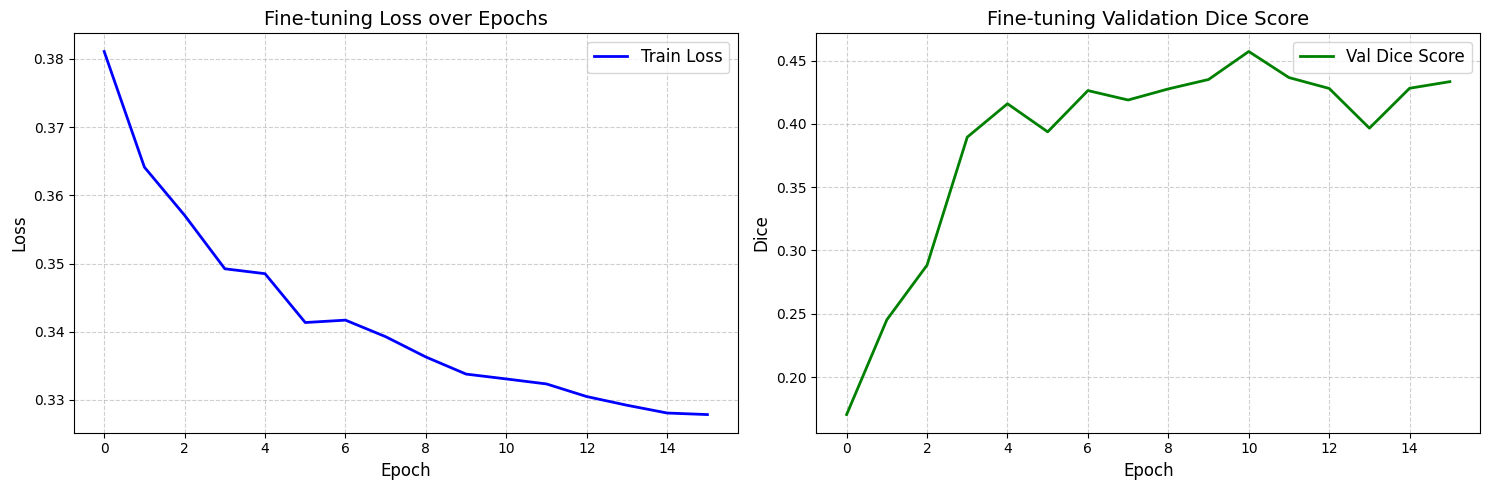

In [3]:
#绘制微调 Loss 和 Dice 曲线
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 左图：Fine-tuning Training Loss
axes[0].plot(train_losses, label='Train Loss', color='blue', linewidth=2)
axes[0].set_title('Fine-tuning Loss over Epochs', fontsize=14)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=12)

# 右图：Fine-tuning Validation Dice
axes[1].plot(val_dices, label='Val Dice Score', color='green', linewidth=2)
axes[1].set_title('Fine-tuning Validation Dice Score', fontsize=14)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Dice', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(fontsize=12)

plt.tight_layout()
plt.show()


# 可视化微调后的预测对比（3x3）

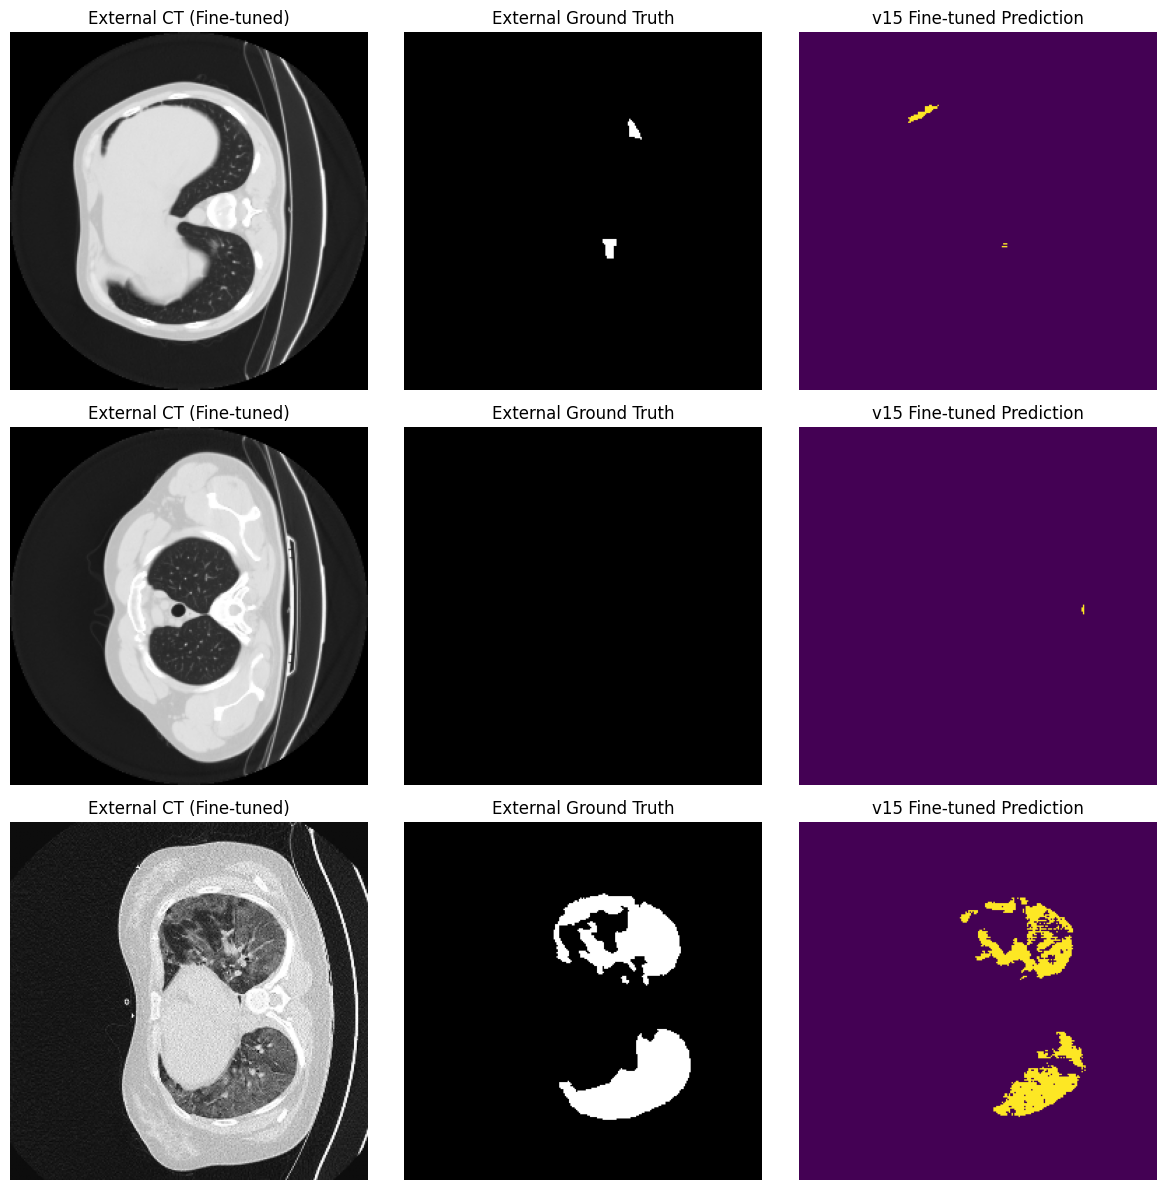

🎉 v15 曲线与可视化预测完成！


In [4]:
# 加载微调后的最佳模型
model.load_state_dict(torch.load("/kaggle/working/best_lung_unet_v15.pth"))
model.eval()

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

with torch.no_grad():
    for i, (images, masks) in enumerate(val_loader):
        if i >= 3: break
        images, masks = images.to(device), masks.to(device)
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        
        # 外部队列CT
        axes[i, 0].imshow(images[0, 0].cpu().numpy(), cmap='gray')
        axes[i, 0].set_title("External CT (Fine-tuned)")
        axes[i, 0].axis('off')
        
        # 真实标签
        axes[i, 1].imshow(masks[0, 0].cpu().numpy(), cmap='gray')
        axes[i, 1].set_title("External Ground Truth")
        axes[i, 1].axis('off')
        
        # 微调后模型预测
        axes[i, 2].imshow(preds[0], cmap='viridis')
        axes[i, 2].set_title("v15 Fine-tuned Prediction")
        axes[i, 2].axis('off')

plt.tight_layout()
plt.show()
print("🎉 v15 曲线与可视化预测完成！")

## 📌 版本 15 学习总结
- **核心突破**：完成了跨数据集的微调（Fine-tuning），成功让模型适应了新数据。
- **技术关键点**：
  1. 跨中心微调必须使用极小的学习率（如 1e-5），否则会导致灾难性遗忘。
  2. 数据预处理（HU 窗宽窗位）必须与原始训练集保持一致，否则模型会崩溃（预测全背景）。
- **结果分析**：外部验证 Dice 从 0.0000 提升至 0.4572。虽然未达到内部测试集的 0.7650，但已证明微调能有效缓解域偏移（Domain Shift）。